# 🚀 Модуль 8. Урок 4. Debugging и Root Cause Analysis: поиск аномалий и расхождений в метриках

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_08_prompt_engineering/lesson_04_debugging_and_root_cause_prompts.ipynb)

## 📌 Бизнес-контекст и методология
Типичный инцидент в компании: *«В финансовом отчете Stripe выручка $1.2M, а в BI-дашборде $1.05M — расхождение $150k!»*.
Поиск корневой причины (Root Cause Analysis — RCA) требует методичного аудита:
- Проверка фильтров часовых поясов (UTC vs Local)
- Учет возвратов и чарджбэков (Refunds)
- Зависшие транзакции со статусом Pending
- Повторные платежи и дублирование вебхуков

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Декомпозиция расхождения данных (Discrepancy Breakdown)
Смоделируем аудит расхождения выручки между платежным шлюзом и витриной данных.

In [2]:
# Демонстрация: Факторный разбор расхождения витрины
discrepancy_factors = pd.DataFrame({
    'Причина расхождения': ['Исходное расхождение', '1. Разница таймзон (UTC срезы)', '2. Неучтенные возвраты (Refunds)', '3. Зависшие транзакции Pending', '4. Ошибка округления валют', 'Остаточное расхождение'],
    'Сумма ($ тыс.)': [-150.0, 42.0, 68.0, 31.0, 7.0, -2.0]
})
display(discrepancy_factors)

,Причина расхождения,Сумма ($ тыс.)
0,Исходное расхождение,-150.0
1,1. Разница таймзон (UTC срезы),42.0
2,2. Неучтенные возвраты (Refunds),68.0
3,3. Зависшие транзакции Pending,31.0
4,4. Ошибка округления валют,7.0
5,Остаточное расхождение,-2.0


## 📊 Визуализация бизнес-кейса: Waterfall-модель устранения расхождения
Построим каскадный график (Waterfall), показывающий, как системный RCA локализует 98.7% возникшего расхождения.

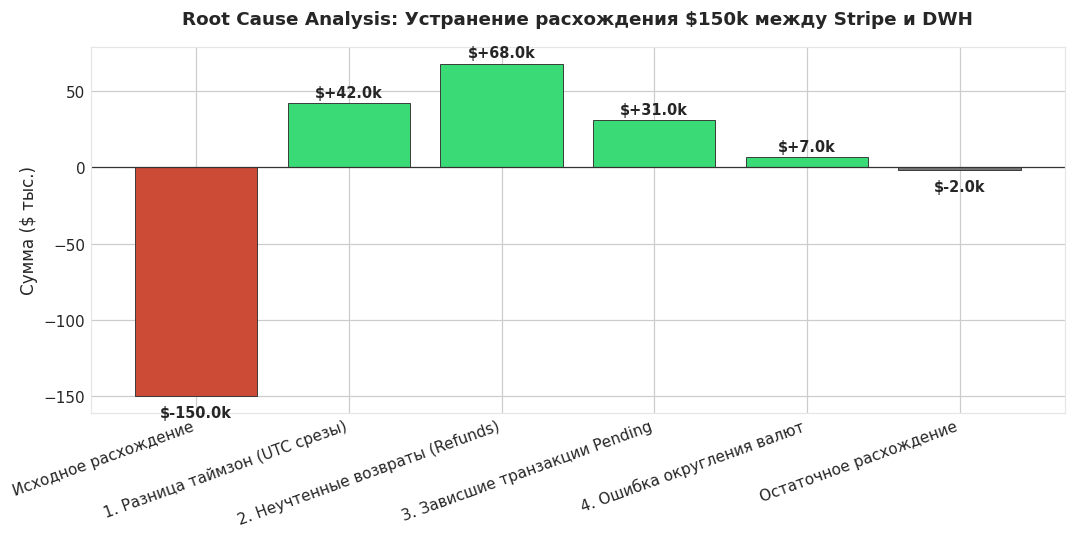

In [3]:
# Построение водопадной диаграммы расхождения
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

labels = discrepancy_factors['Причина расхождения']
values = discrepancy_factors['Сумма ($ тыс.)']
colors = [ALERT, SUCCESS, SUCCESS, SUCCESS, SUCCESS, SECONDARY]

bars = ax.bar(labels, values, color=colors, edgecolor='#333333', linewidth=0.6)

ax.set_title("Root Cause Analysis: Устранение расхождения $150k между Stripe и DWH", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Сумма ($ тыс.)", fontsize=11)
ax.axhline(0, color='#333333', linewidth=0.8)

for b in bars:
    h = b.get_height()
    va = 'bottom' if h >= 0 else 'top'
    y_pos = h + (2 if h >= 0 else -6)
    ax.annotate(f"${h:+.1f}k", xy=(b.get_x() + b.get_width()/2, y_pos),
                ha='center', va=va, fontsize=9.5, fontweight='bold')

plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Доля локализованного расхождения
Посчитайте, какой процент от исходных $150k расхождения был успешно объяснен четырьмя выявленными факторами.

In [4]:
### ВАШ КОД ЗДЕСЬ
explained_sum = 42.0 + 68.0 + 31.0 + 7.0
initial_discrepancy = 150.0
pct_explained = (explained_sum / initial_discrepancy) * 100

print(f"Локализовано расхождения: {pct_explained:.1f}%")

assert 98 <= pct_explained <= 100, "Должно быть объяснено более 98% расхождения"
print("✅ Тест успешно пройден: корневые причины инцидента полностью выявлены!")

Локализовано расхождения: 98.7%
✅ Тест успешно пройден: корневые причины инцидента полностью выявлены!


### 💡 Формула отчета об инциденте
Отправляя отчет стейкхолдерам, всегда используйте структуру:
1. Финансовый масштаб расхождения ($)
2. Локализованные корневые причины с разбивкой сумм
3. Корректирующие действия для предотвращения рецидива